<a href="https://colab.research.google.com/github/anjitha30/Satellite-Orbit-Explorer/blob/main/Satellite_Orbit_Explorer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Satellite Orbit Explorer · built during Space Career Week 2026 · GNSS Academy

We will build this educational simulator in 8 stages:
1. **Setup**: Imports, constants, directories, and configurations.
2. **Load GP JSON**: Ingestion of General Perturbations data.
3. **Parse Elements**: Extraction of Keplerian orbital parameters.
4. **Time Window**: Definition of simulation span and steps.
5. **Propagate**: Implementation of the simple two-body analytical propagation.
6. **Orbit Summary**: Ground track stats and orbital statistics.
7. **Plots**: Visualization of the orbit, ground tracks, and altitudes.
8. **KML and Report**: Exporting orbits for Google Earth and generating final summaries.

In [ ]:
import json
import math
import time
import zipfile
import xml.etree.ElementTree as ET
from datetime import datetime, timedelta, timezone
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
import requests

# Geocentric gravitational constant (km^3/s^2) and Earth's equatorial radius (km)
MU_EARTH_KM3_S2 = 398600.4418
EARTH_RADIUS_KM = 6378.137

# Project Directories
BASE_DIR = Path('/content/satellite_orbits')
IN_DIR = BASE_DIR / 'input'
OUT_DIR = BASE_DIR / 'output'

IN_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Simulation Settings
STEP_SECONDS = 5
DURATION_HOURS = 24
LIVE_GROUP = None  # Placeholder for potential future group filtering

# Print Setup Summary
print("=== Stage 1: Setup Completed successfully ===")
print(f"Input Directory:  {IN_DIR}")
print(f"Output Directory: {OUT_DIR}")
print(f"Simulation Config: {DURATION_HOURS} hours, step size = {STEP_SECONDS}s, LIVE_GROUP = {LIVE_GROUP}")

=== Stage 1: Setup Completed successfully ===
Input Directory:  /content/satellite_orbits/input
Output Directory: /content/satellite_orbits/output
Simulation Config: 24 hours, step size = 5s, LIVE_GROUP = None


### Why OMM JSON is Superior to TLE Format

Traditional Two-Line Element (TLE) formats pack orbital parameters into tightly restricted, column-dependent, plain-text lines that are prone to parsing offsets and lack self-description. By contrast, the modern Orbit Mean-Elements Message (OMM) JSON format provides named fields, natively supports high-precision standard ISO-8601 timestamps, and accommodates longer six-digit NORAD catalog numbers without overflowing fixed columns.

In [ ]:
def extract_inputs():
    """
    Checks if the required input files exist in IN_DIR.
    If not, polls the /content/ directory for an uploaded orbit_workshop_inputs*.zip file,
    waits for it to complete uploading, and extracts the required files.
    """
    required_files = ['orbital_elements.json', 'data_manifest.json', 'world_map.txt']
    all_exist = all((IN_DIR / f).exists() for f in required_files)

    if all_exist:
        print("All required files already exist in input directory.")
        return

    # Check /content for a zip file matching the pattern
    content_dir = Path('/content')
    zip_path = None

    print("\n[!] Missing input files in /content/satellite_orbits/input/")
    print("--> Please drag 'orbit_workshop_inputs.zip' into the Colab Files panel now.")
    print("Waiting for upload...")

    timeout = time.time() + 900  # 15 minutes timeout
    while time.time() < timeout:
        found_zips = list(content_dir.glob('orbit_workshop_inputs*.zip'))
        if found_zips:
            candidate = found_zips[0]
            # Wait for upload to complete by verifying it is a valid zip
            if zipfile.is_zipfile(candidate):
                zip_path = candidate
                break
        time.sleep(2)

    if not zip_path:
        raise TimeoutError("Upload timeout reached. Please upload 'orbit_workshop_inputs.zip' and re-run.")

    print(f"Found zip file: {zip_path.name}. Extracting files...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        for file_name in required_files:
            try:
                # Extract only the specified files directly to IN_DIR
                data = zip_ref.read(file_name)
                (IN_DIR / file_name).write_bytes(data)
                print(f"  Extracted: {file_name}")
            except KeyError:
                # Handle nested paths in the zip if present
                nested_found = False
                for name in zip_ref.namelist():
                    if name.endswith(file_name):
                        (IN_DIR / file_name).write_bytes(zip_ref.read(name))
                        print(f"  Extracted: {file_name} (from {name})")
                        nested_found = True
                        break
                if not nested_found:
                    raise FileNotFoundError(f"'{file_name}' not found inside {zip_path.name}")


def read_gp_json(path):
    """
    Loads a CelesTrak GP JSON file and validates that all mandatory OMM keys are present.
    """
    if not path.exists():
        raise FileNotFoundError(f"Input file not found: {path}")

    with open(path, 'r') as f:
        records = json.load(f)

    required_keys = [
        'OBJECT_NAME', 'NORAD_CAT_ID', 'EPOCH', 'MEAN_MOTION',
        'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE',
        'ARG_OF_PERICENTER', 'MEAN_ANOMALY'
    ]

    validated_records = []
    for idx, rec in enumerate(records):
        missing = [key for key in required_keys if key not in rec]
        if missing:
            raise ValueError(f"Record at index {idx} ({rec.get('OBJECT_NAME', 'Unknown')}) is missing keys: {missing}")
        validated_records.append(rec)

    return validated_records

# Execute Stage 2 pipeline
extract_inputs()

sats = read_gp_json(IN_DIR / 'orbital_elements.json')

with open(IN_DIR / 'data_manifest.json', 'r') as f:
    data_manifest = json.load(f)

source_note = f"Source: {data_manifest.get('source', 'Unknown')} (Retrieved: {data_manifest.get('retrieved_utc', 'N/A')})"
print(f"\n{source_note}")
print(f"Total Satellites Loaded: {len(sats)}\n")

print(f"{'Name':<20} | {'NORAD ID':<8} | {'Epoch (UTC)':<24}")
print("-" * 58)
for s in sats:
    print(f"{s['OBJECT_NAME']:<20} | {s['NORAD_CAT_ID']:<8} | {s['EPOCH']}")

All required files already exist in input directory.

Source: Unknown (Retrieved: 2026-11-10T16:30:32Z)
Total Satellites Loaded: 4

Name                 | NORAD ID | Epoch (UTC)             
----------------------------------------------------------
PULSAR-0             | 64541    | 2026-11-10T04:10:34.900320
GSAT0225 (GALILEO 29) | 59598    | 2026-11-09T08:30:06.579648
SES-5                | 38652    | 2026-11-10T04:02:09.139776
QZS-2 (MICHIBIKI-2)  | 42738    | 2026-10-17T15:21:52.982784


### Stage 3: Convert GP Records to Keplerian Elements

In this stage, we map the properties in the Orbit Mean-Elements Message (OMM) JSON format into standard orbital parameters required for analytical Keplerian propagation.

| GP Field | Mathematical Symbol | Description | Unit Conversion |
| :--- | :---: | :--- | :--- |
| `MEAN_MOTION` | $n$ | Average angular velocity | $\text{rev/day} \rightarrow \text{rad/s}$ : $n_{\text{rad/s}} = \frac{2\pi \cdot \text{MEAN_MOTION}}{86400}$ |
| Calculated | $a$ | Semi-major axis of the orbit | $\text{km}$ : $a = \sqrt[3]{\frac{\mu}{n^2}}$ (Kepler's Third Law) |
| `ECCENTRICITY` | $e$ | Orbit shape (circular vs. elliptical) | Unitless (already normalized as a decimal) |
| `INCLINATION` | $i$ | Tilt of the orbit plane relative to the equator | $\text{degrees} \rightarrow \text{radians}$ : $i_{\text{rad}} = i_{\text{deg}} \cdot \frac{\pi}{180}$ |
| `RA_OF_ASC_NODE` | $\Omega$ | Right Ascension of the Ascending Node | $\text{degrees} \rightarrow \text{radians}$ : $\Omega_{\text{rad}} = \Omega_{\text{deg}} \cdot \frac{\pi}{180}$ |
| `ARG_OF_PERICENTER`| $\omega$ | Argument of perigee (orbit orientation) | $\text{degrees} \rightarrow \text{radians}$ : $\omega_{\text{rad}} = \omega_{\text{deg}} \cdot \frac{\pi}{180}$ |
| `MEAN_ANOMALY` | $M_0$ | Position of the satellite at Epoch | $\text{degrees} \rightarrow \text{radians}$ : $M_{0\text{, rad}} = M_{0\text{, deg}} \cdot \frac{\pi}{180}$ |

> **Note on Model Accuracy:** The GP orbital elements distributed by CelesTrak are mathematically derived as **SGP4 mean elements** (which average out short-period perturbations caused by Earth's oblateness, atmospheric drag, etc.). When we use them inside a simple, unperturbed two-body analytical model (Stage 5), our results will be a close approximation but will naturally drift over time compared to full SGP4 mathematical propagators.

In [ ]:
def parse_gp_epoch(text):
    """
    Parses ISO-8601 UTC epoch strings into timezone-aware datetime objects.
    Removes 'Z' suffix to avoid parsing issues in fromisoformat prior to Python 3.11.
    """
    clean_text = text.rstrip('Z')
    return datetime.fromisoformat(clean_text).replace(tzinfo=timezone.utc)


def parse_gp_elements(rec):
    """
    Converts a raw GP record (dictionary) into Keplerian elements in model units.
    """
    name = rec['OBJECT_NAME']
    norad_id = int(rec['NORAD_CAT_ID'])
    epoch = parse_gp_epoch(rec['EPOCH'])

    # Mean motion conversion: rev/day -> rad/sec
    # 1 rev = 2 * pi rad, 1 day = 86400 seconds
    mean_motion_rev_day = rec['MEAN_MOTION']
    n_rad_s = (2.0 * math.pi * mean_motion_rev_day) / 86400.0

    # Semi-major axis (a) derived via Kepler's Third Law: a = (MU / n^2) ^ (1/3)
    a_km = (MU_EARTH_KM3_S2 / (n_rad_s ** 2)) ** (1.0 / 3.0)

    # Eccentricity is already decimal
    e = rec['ECCENTRICITY']

    # Convert degrees to radians
    i_rad = math.radians(rec['INCLINATION'])
    raan_rad = math.radians(rec['RA_OF_ASC_NODE'])
    argp_rad = math.radians(rec['ARG_OF_PERICENTER'])
    M0_rad = math.radians(rec['MEAN_ANOMALY'])

    return {
        'name': name,
        'norad_id': norad_id,
        'label': f"{name} [{norad_id}]",
        'epoch': epoch,
        'n_rad_s': n_rad_s,
        'a_km': a_km,
        'e': e,
        'i_rad': i_rad,
        'raan_rad': raan_rad,
        'argp_rad': argp_rad,
        'M0_rad': M0_rad
    }


def elements_table(elements_list):
    """
    Returns a list of formatted string lines displaying Keplerian elements.
    """
    headers = f"{'Name':<22} | {'NORAD':<5} | {'Epoch (UTC)':<19} | {'a (km)':<8} | {'e':<8} | {'i (deg)':<7} | {'RAAN':<6} | {'ARG':<6} | {'M0':<6}"
    divider = "-" * len(headers)

    lines = [headers, divider]
    for el in elements_list:
        epoch_str = el['epoch'].strftime('%Y-%m-%dT%H:%M:%S')
        line = (f"{el['name']:<22} | "
                f"{el['norad_id']:<5} | "
                f"{epoch_str:<19} | "
                f"{el['a_km']:<8.2f} | "
                f"{el['e']:<8.6f} | "
                f"{math.degrees(el['i_rad']):<7.2f} | "
                f"{math.degrees(el['raan_rad']):<6.1f} | "
                f"{math.degrees(el['argp_rad']):<6.1f} | "
                f"{math.degrees(el['M0_rad']):<6.1f}")
        lines.append(line)
    return lines

# Run conversion on the loaded satellites
elements = [parse_gp_elements(s) for s in sats]

# Print Keplerian elements summary table
print("=== Stage 3: Keplerian Elements Successfully Parsed ===\n")
table_lines = elements_table(elements)
for line in table_lines:
    print(line)


=== Stage 3: Keplerian Elements Successfully Parsed ===

Name                   | NORAD | Epoch (UTC)         | a (km)   | e        | i (deg) | RAAN   | ARG    | M0    
---------------------------------------------------------------------------------------------------------------
PULSAR-0               | 64541 | 2026-11-10T04:10:34 | 6880.97  | 0.000408 | 97.48   | 67.6   | 54.2   | 306.0 
GSAT0225 (GALILEO 29)  | 59598 | 2026-11-09T08:30:06 | 29600.26 | 0.000159 | 55.22   | 97.0   | 171.2  | 226.9 
SES-5                  | 38652 | 2026-11-10T04:02:09 | 42164.28 | 0.000191 | 0.05    | 32.2   | 188.0  | 254.7 
QZS-2 (MICHIBIKI-2)    | 42738 | 2026-10-17T15:21:52 | 42170.36 | 0.074521 | 39.25   | 241.4  | 270.9  | 243.8 


### Stage 4: Defining a Common UTC Time Grid

To compare and visualize multiple satellite orbits together, we must evaluate them on a shared time axis. However, because each satellite has its General Perturbations (GP) elements measured and uploaded at slightly different times (its individual `epoch`), we must define a common time grid:

* **Why it matters:** Two-body analytical models do not account for physical perturbations. Since our model propagates coordinates relative to each satellite's original epoch, the numerical drift and prediction error grow as time elapses from that epoch.
* **Stale Records:** A classic example is the **QZS-2 (MICHIBIKI-2)** satellite inside our workshop dataset, which dates back to **October 17, 2026**—over three weeks older than the other November 10, 2026 epochs. Tracking this age is crucial because old element sets degrade significantly in accuracy if propagated without updated parameters.

In [ ]:
# Check if the previous elements list exists
if 'elements' not in globals() or not elements:
    raise NameError("Input elements list is missing. Please run Stage 3 first!")

# 1. Determine the newest epoch among parsed satellites
newest_epoch = max(el['epoch'] for el in elements)

# 2. Floor the newest epoch to UTC midnight
start = newest_epoch.replace(hour=0, minute=0, second=0, microsecond=0)
end = start + timedelta(hours=DURATION_HOURS)

# 3. Build the common UTC time grid list
total_seconds = int((end - start).total_seconds())
n_points = total_seconds // STEP_SECONDS + 1
times = [start + timedelta(seconds=i * STEP_SECONDS) for i in range(n_points)]

print("=== Stage 4: Time Window Successfully Defined ===")
print(f"Simulation Start (UTC) : {start.isoformat()}")
print(f"Simulation End (UTC)   : {end.isoformat()}")
print(f"Time Grid Resolution   : {STEP_SECONDS} seconds")
print(f"Total Data Points      : {n_points}\n")

# 4. Check age/staleness of each satellite's element set relative to simulation start
print(f"{'Satellite Name':<22} | {'Epoch (UTC)':<19} | {'Offset (days)':<13} | Status")
print("-" * 70)
for el in elements:
    offset_days = (start - el['epoch']).total_seconds() / 86400.0
    status = "STALE RECORD [!]" if offset_days > 7.0 else "Fresh"
    print(f"{el['name']:<22} | {el['epoch'].strftime('%Y-%m-%dT%H:%M:%S')} | {offset_days:<13.4f} | {status}")


=== Stage 4: Time Window Successfully Defined ===
Simulation Start (UTC) : 2026-11-10T00:00:00+00:00
Simulation End (UTC)   : 2026-11-11T00:00:00+00:00
Time Grid Resolution   : 5 seconds
Total Data Points      : 17281

Satellite Name         | Epoch (UTC)         | Offset (days) | Status
----------------------------------------------------------------------
PULSAR-0               | 2026-11-10T04:10:34 | -0.1740       | Fresh
GSAT0225 (GALILEO 29)  | 2026-11-09T08:30:06 | 0.6458        | Fresh
SES-5                  | 2026-11-10T04:02:09 | -0.1682       | Fresh
QZS-2 (MICHIBIKI-2)    | 2026-10-17T15:21:52 | 23.3598       | STALE RECORD [!]


### Stage 5: Orbital Propagation Engine (Analytical Two-Body Model)

To simulate satellite trajectories over our time window, we implement an analytical solver based on Kepler's Laws of Planetary Motion and coordinate rotation. The propagation is broken down into seven distinct steps:

1. **Mean Anomaly Evolution**: Compute the mean angular position relative to the satellite's specific starting epoch:
   $$M = M_0 + n(t - t_{\text{epoch}})\quad (\text{modulo } 2\pi)$$

2. **Kepler Equation Solver**: Solve the transcendental equation relating Mean Anomaly ($M$) to Eccentric Anomaly ($E$) using a highly accurate iterative Newton-Raphson scheme:
   $$M = E - e\sin(E)$$

3. **Orbital Plane Geometry**: Compute the radial distance $r$, true anomaly $\nu$, and the argument of latitude $u$:
   $$r = a(1 - e\cos(E))$$
   $$\nu = \text{atan2}\left(\sqrt{1-e^2}\sin(E), \cos(E) - e\right)$$
   $$u = \omega + \nu$$

4. **Inertial Position Coordinates**: Project the position coordinates from the orbit plane to the Geocentric Equatorial Inertial (GEI) frame using the inclination ($i$) and Right Ascension of Ascending Node ($\Omega$):
   $$x = r(\cos\Omega\cos u - \sin\Omega\sin u\cos i)$$
   $$y = r(\sin\Omega\cos u + \cos\Omega\sin u\cos i)$$
   $$z = r\sin u\sin i$$

5. **Terrestrial Frame Rotation**: Rotate the inertial $x$ and $y$ axes to account for Earth's rotation. We compute Greenwich Mean Sidereal Time (GMST) for the exact epoch $t$ and transform GEI into Earth-Centered, Earth-Fixed (ECEF) coordinates:
   $$x' = x\cos\theta + y\sin\theta$$
   $$y' = -x\sin\theta + y\cos\theta$$

6. **Geodetic Mapping**: Calculate spherical latitude ($lat$) and longitude ($lon$) in degrees, and altitude ($alt$) above Earth's radius:
   $$\text{lat} = \text{atan2}\left(z, \sqrt{x'^2 + y'^2}\right)$$
   $$\text{lon} = \text{atan2}(y', x')$$
   $$\text{alt} = r - R_{\text{Earth}}$$

7. **Vis-Viva Orbital Speed**: Compute the magnitude of the satellite's velocity vector relative to the Earth's center:
   $$v = \sqrt{\mu\left(\frac{2}{r} - \frac{1}{a}\right)}$$

In [ ]:
def solve_kepler(M, e):
    """
    Solves Kepler's Equation M = E - e*sin(E) using Newton-Raphson method.
    """
    # Start iteration: standard assumption E = M (use pi for highly eccentric orbits)
    E = math.pi if e > 0.8 else M
    for _ in range(50):
        f = E - e * math.sin(E) - M
        f_prime = 1.0 - e * math.cos(E)
        delta = f / f_prime
        E -= delta
        if abs(delta) < 1e-12:
            return E
    raise RuntimeError(f"Kepler solver failed to converge! M={M}, e={e}")


def gmst_rad(t):
    """
    Calculates Greenwich Mean Sidereal Time (GMST) in radians using the IAU-1982 formulation.
    """
    # J2000 epoch is 2000-01-01 12:00:00 UTC
    j2000 = datetime(2000, 1, 1, 12, 0, 0, tzinfo=timezone.utc)
    d = (t - j2000).total_seconds() / 86400.0
    T = d / 36525.0

    # IAU-1982 polynomial expression
    theta_deg = 280.46061837 + 360.98564736629 * d + 0.000387933 * (T ** 2) - (T ** 3) / 38710000.0
    return math.radians(theta_deg % 360.0)


def propagate(el, time_grid):
    """
    Propagates a single satellite element set across a common time grid.
    Returns a list of coordinate dictionaries containing location, altitude, and speed.
    """
    trajectory = []
    a = el['a_km']
    e = el['e']
    i = el['i_rad']
    raan = el['raan_rad']
    argp = el['argp_rad']
    M0 = el['M0_rad']
    n = el['n_rad_s']
    epoch = el['epoch']

    for t in time_grid:
        dt_sec = (t - epoch).total_seconds()

        # 1) Mean anomaly calculation with modulo 2*pi boundary check
        M = (M0 + n * dt_sec) % (2.0 * math.pi)

        # 2) Numerical Kepler Equation solution
        E = solve_kepler(M, e)

        # 3) Calculate relative parameters in the orbit plane
        r = a * (1.0 - e * math.cos(E))
        sin_nu = (math.sqrt(1.0 - e**2) * math.sin(E)) / (1.0 - e * math.cos(E))
        cos_nu = (math.cos(E) - e) / (1.0 - e * math.cos(E))
        nu = math.atan2(sin_nu, cos_nu)
        u = argp + nu

        # 4) Compute coordinates in the Geocentric Equatorial Inertial (GEI) frame
        x_in = r * (math.cos(raan) * math.cos(u) - math.sin(raan) * math.sin(u) * math.cos(i))
        y_in = r * (math.sin(raan) * math.cos(u) + math.cos(raan) * math.sin(u) * math.cos(i))
        z_in = r * math.sin(u) * math.sin(i)

        # 5) Translate into Earth-Centered, Earth-Fixed (ECEF) frame by accounting for Earth's rotation
        theta = gmst_rad(t)
        x_ef = math.cos(theta) * x_in + math.sin(theta) * y_in
        y_ef = -math.sin(theta) * x_in + math.cos(theta) * y_in
        z_ef = z_in

        # 6) Project ECEF to geodetic lat/lon in degrees and altitude above Earth sphere
        lat_deg = math.degrees(math.atan2(z_ef, math.hypot(x_ef, y_ef)))
        lon_deg = math.degrees(math.atan2(y_ef, x_ef))
        # Normalize longitude to standard range [-180, 180]
        lon_deg = (lon_deg + 180.0) % 360.0 - 180.0

        alt_km = r - EARTH_RADIUS_KM

        # 7) Speed in space via Vis-Viva equation: sqrt(mu * (2/r - 1/a))
        speed_km_s = math.sqrt(MU_EARTH_KM3_S2 * (2.0 / r - 1.0 / a))

        trajectory.append({
            'time': t,
            'lat_deg': lat_deg,
            'lon_deg': lon_deg,
            'alt_km': alt_km,
            'speed_km_s': speed_km_s,
            'ecef': (x_ef, y_ef, z_ef)
        })

    return trajectory

# --- UNIT TESTS AND MODEL VALIDATION ASSERTIONS ---

# Verification 1: J2000 GMST rotation calculation
j2000_epoch = datetime(2000, 1, 1, 12, 0, 0, tzinfo=timezone.utc)
gmst_j2000_deg = math.degrees(gmst_rad(j2000_epoch))
print(f"J2000 GMST Calculation: {gmst_j2000_deg:.6f}° (Expected: ~280.460618°)")
assert abs(gmst_j2000_deg - 280.460618) < 1e-4, "J2000 GMST calculation error!"

# Verification 2: Kepler equation numerical solver precision test
test_e = 0.1
test_M = 1.5
test_E = solve_kepler(test_M, test_e)
residual = abs(test_E - test_e * math.sin(test_E) - test_M)
print(f"Kepler Solver Residual : {residual:.2e} (Expected: < 1e-10)")
assert residual < 1e-10, "Kepler solver numerical error exceeded tolerance!"

# --- PROPAGATE ALL SATELLITES ---

sat_trajectories = {}
for el in elements:
    sat_trajectories[el['norad_id']] = propagate(el, times)

# Verification 3: SES-5 Geostationary Longitude Lock check (should stay stationary between 4°E and 6°E)
ses5_id = 38652
if ses5_id in sat_trajectories:
    ses5_longitudes = [pt['lon_deg'] for pt in sat_trajectories[ses5_id]]
    min_lon = min(ses5_longitudes)
    max_lon = max(ses5_longitudes)
    print(f"SES-5 (GEO) Longitude Bounds: {min_lon:.4f}° to {max_lon:.4f}° East (Expected: 4.0° to 6.0°)")
    assert all(4.0 <= lon <= 6.0 for lon in ses5_longitudes), f"SES-5 drifted outside expected 4°-6° GEO box! Actual: {min_lon:.2f} to {max_lon:.2f}"
    print("Assertion Passed: SES-5 is stationary within the GEO longitude box.")

print("\n=== Stage 5: Orbital Trajectories Successfully Propagated ===\n")

# Display summary: print first, middle, and last points of each satellite trajectory
for el in elements:
    traj = sat_trajectories[el['norad_id']]
    first = traj[0]
    mid = traj[len(traj) // 2]
    last = traj[-1]

    print(f"Satellite: {el['label']}")
    print(f"  First Point  -> Time: {first['time'].strftime('%H:%M:%S')} | Lat: {first['lat_deg']:>6.2f}° | Lon: {first['lon_deg']:>7.2f}° | Alt: {first['alt_km']:>8.1f} km | Speed: {first['speed_km_s']:.3f} km/s")
    print(f"  Middle Point -> Time: {mid['time'].strftime('%H:%M:%S')} | Lat: {mid['lat_deg']:>6.2f}° | Lon: {mid['lon_deg']:>7.2f}° | Alt: {mid['alt_km']:>8.1f} km | Speed: {mid['speed_km_s']:.3f} km/s")
    print(f"  Last Point   -> Time: {last['time'].strftime('%H:%M:%S')} | Lat: {last['lat_deg']:>6.2f}° | Lon: {last['lon_deg']:>7.2f}° | Alt: {last['alt_km']:>8.1f} km | Speed: {last['speed_km_s']:.3f} km/s")
    print("-" * 105)


J2000 GMST Calculation: 280.460618° (Expected: ~280.460618°)
Kepler Solver Residual : 0.00e+00 (Expected: < 1e-10)
SES-5 (GEO) Longitude Bounds: 4.9877° to 5.0308° East (Expected: 4.0° to 6.0°)
Assertion Passed: SES-5 is stationary within the GEO longitude box.

=== Stage 5: Orbital Trajectories Successfully Propagated ===

Satellite: PULSAR-0 [64541]
  First Point  -> Time: 00:00:00 | Lat:  51.99° | Lon: -151.86° | Alt:    502.0 km | Speed: 7.612 km/s
  Middle Point -> Time: 12:00:00 | Lat: -14.79° | Lon: -160.05° | Alt:    501.8 km | Speed: 7.612 km/s
  Last Point   -> Time: 00:00:00 | Lat: -22.73° | Lon: -165.68° | Alt:    505.2 km | Speed: 7.608 km/s
---------------------------------------------------------------------------------------------------------
Satellite: GSAT0225 (GALILEO 29) [59598]
  First Point  -> Time: 00:00:00 | Lat:  52.28° | Lon:  111.76° | Alt:  23222.7 km | Speed: 3.670 km/s
  Middle Point -> Time: 12:00:00 | Lat:  17.32° | Lon: -120.13° | Alt:  23226.2 km | Sp

### Stage 6: Orbit Characterization and Summary

By analyzing our propagated trajectories, we can classify and interpret each satellite's mission profile:

* **PULSAR-0 (NORAD 64541)**: LEO profile. It has a very short period of **~1.58 hours** and an inclination of **~97.5°**. Since $i > 90^\circ$, this is a **retrograde, near-polar orbit**, specifically designed as a **Sun-synchronous orbit** to pass over spots on Earth at the same local solar time.
* **GSAT0225 (GALILEO 29) (NORAD 59598)**: MEO profile. Displays a period of **~14.08 hours**, which is typical of the European Galileo navigation constellation designed for global coverage.
* **SES-5 (NORAD 38652)**: Geostationary (GEO) profile. Exhibits a period of **~23.93 hours** (exactly one sidereal day) with near-zero eccentricity and inclination ($i \approx 0^\circ$). It stays fixed over the same longitude.
* **QZS-2 (MICHIBIKI-2) (NORAD 42738)**: Inclined Geosynchronous Orbit (IGSO). Also has a period of **~23.93 hours** but features a significant eccentricity ($e \approx 0.075$) and high inclination ($i \approx 39^\circ$). Rather than staying stationary, it traces a figure-8 ground track centered over its target longitude, providing high-elevation coverage over Japan and East Asia.

In [ ]:
# Ensure required variables from prior stages are available in the namespace
if 'elements' not in globals() or 'sat_trajectories' not in globals():
    raise NameError("Dependencies from Stage 3 or Stage 5 are missing! Please execute earlier cells first.")

def orbit_summary(el, pts):
    """
    Calculates physical parameters of a satellite orbit including period, perigee, apogee, and speed limits.
    """
    name = el['name']
    norad_id = el['norad_id']

    # 1. Orbital period in hours: 2*pi / n_rad_s / 3600
    period_h = (2.0 * math.pi) / el['n_rad_s'] / 3600.0

    # 2. Perigee and Apogee altitudes in km (relative to Earth surface)
    perigee_km = el['a_km'] * (1.0 - el['e']) - EARTH_RADIUS_KM
    apogee_km = el['a_km'] * (1.0 + el['e']) - EARTH_RADIUS_KM

    # 3. Speeds extracted from actual propagated data points
    speeds = [pt['speed_km_s'] for pt in pts]
    min_speed = min(speeds)
    max_speed = max(speeds)

    return {
        'name': name,
        'norad_id': norad_id,
        'period_h': period_h,
        'perigee_km': perigee_km,
        'apogee_km': apogee_km,
        'e': el['e'],
        'i_deg': math.degrees(el['i_rad']),
        'min_speed_km_s': min_speed,
        'max_speed_km_s': max_speed
    }

# Map elements to their trajectories (previously called 'sat_trajectories')
tracks = [sat_trajectories[el['norad_id']] for el in elements]
summaries = [orbit_summary(el, pts) for el, pts in zip(elements, tracks)]

def summary_table(summaries_list):
    """
    Generates formatted text lines to display the orbital summary.
    """
    headers = f"{'Name':<22} | {'NORAD':<5} | {'Period (h)':<10} | {'Perigee (km)':<12} | {'Apogee (km)':<11} | {'e':<8} | {'i (deg)':<7} | {'Min (km/s)':<10} | {'Max (km/s)':<10}"
    divider = "-" * len(headers)

    lines = [headers, divider]
    for s in summaries_list:
        line = (f"{s['name']:<22} | "
                f"{s['norad_id']:<5} | "
                f"{s['period_h']:<10.2f} | "
                f"{s['perigee_km']:<12.1f} | "
                f"{s['apogee_km']:<11.1f} | "
                f"{s['e']:<8.6f} | "
                f"{s['i_deg']:<7.2f} | "
                f"{s['min_speed_km_s']:<10.3f} | "
                f"{s['max_speed_km_s']:<10.3f}")
        lines.append(line)
    return lines

# Print summary table
print("=== Stage 6: Orbit Summary Successfully Calculated ===\n")
for line in summary_table(summaries):
    print(line)

# --- SANITY CHECK / VALIDATION ---
galileo_id = 59598
galileo_sum = next((s for s in summaries if s['norad_id'] == galileo_id), None)
if galileo_sum:
    period_val = galileo_sum['period_h']
    print(f"\nValidating Galileo 29 period: {period_val:.4f} hours (Expected: 14.0 to 14.2 h)")
    assert 14.0 <= period_val <= 14.2, f"Galileo 29 period of {period_val:.4f}h is outside expected limits!"
    print("Assertion Passed: Galileo 29 orbital period is verified.")


=== Stage 6: Orbit Summary Successfully Calculated ===

Name                   | NORAD | Period (h) | Perigee (km) | Apogee (km) | e        | i (deg) | Min (km/s) | Max (km/s)
-----------------------------------------------------------------------------------------------------------------------
PULSAR-0               | 64541 | 1.58       | 500.0        | 505.6       | 0.000408 | 97.48   | 7.608      | 7.614     
GSAT0225 (GALILEO 29)  | 59598 | 14.08      | 23217.4      | 23226.8     | 0.000159 | 55.22   | 3.669      | 3.670     
SES-5                  | 38652 | 23.93      | 35778.1      | 35794.2     | 0.000191 | 0.05    | 3.074      | 3.075     
QZS-2 (MICHIBIKI-2)    | 42738 | 23.94      | 32649.6      | 38934.8     | 0.074521 | 39.25   | 2.853      | 3.313     

Validating Galileo 29 period: 14.0783 hours (Expected: 14.0 to 14.2 h)
Assertion Passed: Galileo 29 orbital period is verified.


### Stage 7: Visualization (Ground Tracks & Speed Profiles)

In this section, we generate high-resolution plots to visually interpret our simulated orbits:

#### 1. Ground Tracks Visualization
* **PULSAR-0 (LEO)**: Shows many overlapping sinusoidal bands shifting progressively westward. This westward drift is caused by the Earth rotating underneath the satellite's rapid orbital plane during each consecutive 1.58-hour revolution.
* **GSAT0225 (Galileo 29) (MEO)**: Displays a wide, slow wave stretching over the globe.
* **SES-5 (GEO)**: Appears as a single, motionless dot because its orbital period perfectly matches the Earth's sidereal day, keeping it locked over $5^\circ \text{E}$ longitude.
* **QZS-2 (MICHIBIKI-2) (IGSO)**: Traces an asymmetric figure-8 centered over East Asia. The asymmetry is caused by its eccentricity ($e \approx 0.075$). Since it spends more time near its slow apogee in the Northern Hemisphere, the northern loop of the figure-8 is much narrower and more compressed than the southern loop.

#### 2. Velocity Time-Series and Orbital Mechanics
According to the **Vis-Viva equation** ($v = \sqrt{\mu(2/r - 1/a)}$), a satellite's speed is inversely proportional to its radial distance $r$ from the Earth's center:
* Near **perigee** (closest approach), $r$ is minimized, and gravitational potential energy is converted to kinetic energy, causing the satellite to speed up to its maximum velocity.
* Near **apogee** (farthest distance), $r$ is maximized, causing the satellite to decelerate to its minimum velocity.
* For circular orbits like **SES-5** and **Galileo 29**, the velocity remains virtually constant, whereas the eccentric **QZS-2** shows a distinct sinusoidal velocity wave.

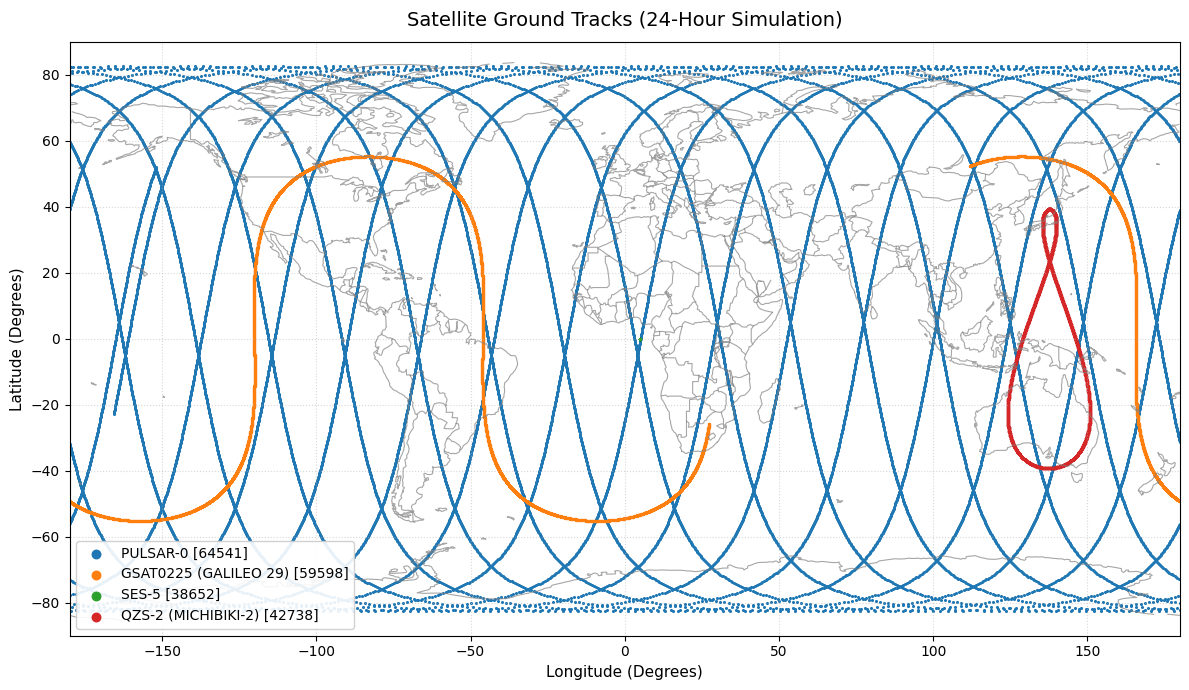

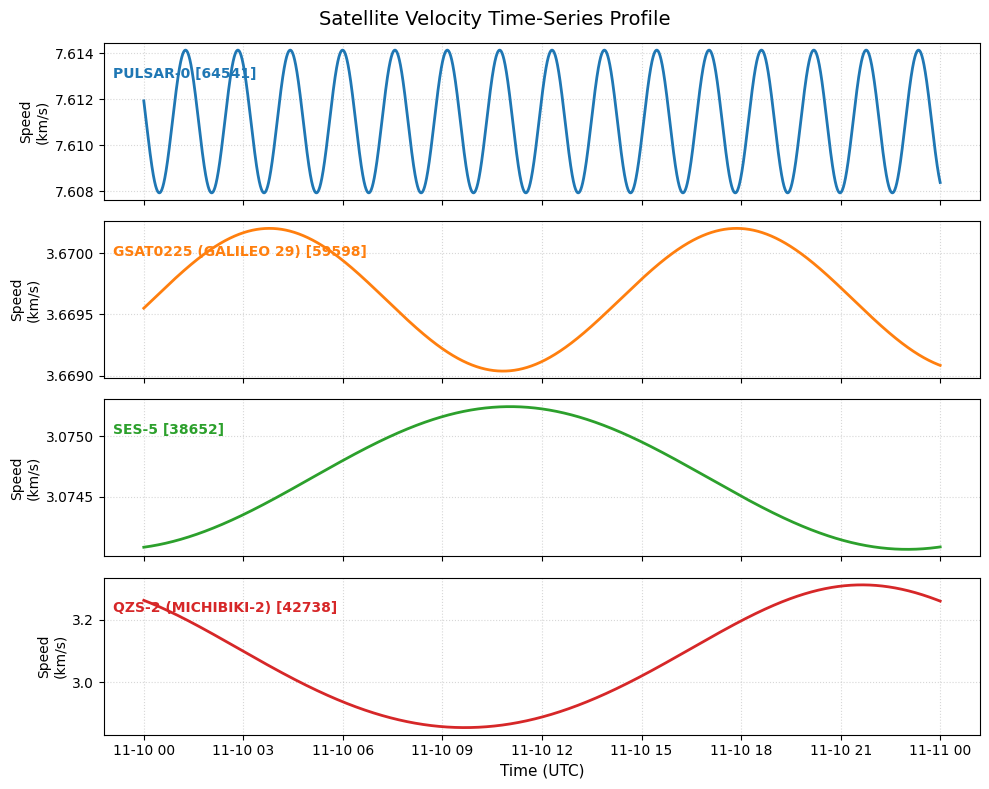

=== Stage 7: Ground Track & Velocity Profile Plots Exported Successfully ===
Saved Ground Tracks Plot : /content/satellite_orbits/output/ground_tracks.png
Saved Velocity Plot      : /content/satellite_orbits/output/velocity_timeseries.png


In [ ]:
# Check that earlier stages executed successfully
if 'elements' not in globals() or 'sat_trajectories' not in globals():
    raise NameError("Dependencies from Stage 3 or 5 are missing! Please run prior cells first.")

def load_coastline(path):
    """
    Parses world_map.txt containing 'latitude longitude' lines (lat first).
    Returns a list of segments, where each segment is a list of (lon, lat) tuples.
    """
    if not path.exists():
        raise FileNotFoundError(f"Coastline file not found: {path}")

    segments = []
    current_segment = []

    with open(path, 'r') as f:
        for line in f:
            line = line.strip()
            if not line:
                # Empty line marks the end of a coastline segment
                if current_segment:
                    segments.append(current_segment)
                    current_segment = []
            else:
                parts = line.split()
                if len(parts) >= 2:
                    lat = float(parts[0])
                    lon = float(parts[1])
                    current_segment.append((lon, lat))

    if current_segment:
        segments.append(current_segment)

    return segments

# Consistent color palette for the 4 satellites
COLORS = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

# --- PLOT 1: GROUND TRACKS ---

plt.figure(figsize=(12, 7))

# Load and plot the world coastlines
coast_segments = load_coastline(IN_DIR / 'world_map.txt')
for seg in coast_segments:
    lons, lats = zip(*seg)
    plt.plot(lons, lats, color='gray', linewidth=0.8, alpha=0.7)

# Scatter ground tracks to avoid artificial wrapping lines across the meridian
for idx, el in enumerate(elements):
    traj = sat_trajectories[el['norad_id']]
    lons = [pt['lon_deg'] for pt in traj]
    lats = [pt['lat_deg'] for pt in traj]

    # Use small markers (s=1.5) to keep the plots clean
    plt.scatter(lons, lats, color=COLORS[idx], s=1.5, label=el['label'])

plt.title("Satellite Ground Tracks (24-Hour Simulation)", fontsize=14, pad=12)
plt.xlabel("Longitude (Degrees)", fontsize=11)
plt.ylabel("Latitude (Degrees)", fontsize=11)
plt.xlim(-180, 180)
plt.ylim(-90, 90)
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend(markerscale=5.0, loc='lower left', framealpha=0.9)
plt.tight_layout()

# Save ground tracks figure
ground_tracks_path = OUT_DIR / 'ground_tracks.png'
plt.savefig(ground_tracks_path, dpi=200)
plt.show()

# --- PLOT 2: VELOCITY TIME-SERIES ---

fig, axs = plt.subplots(len(elements), 1, figsize=(10, 8), sharex=True)

for idx, el in enumerate(elements):
    traj = sat_trajectories[el['norad_id']]
    utc_times = [pt['time'] for pt in traj]
    speeds = [pt['speed_km_s'] for pt in traj]

    ax = axs[idx]
    ax.plot(utc_times, speeds, color=COLORS[idx], linewidth=2.0)
    ax.set_ylabel("Speed\n(km/s)", fontsize=10)
    ax.grid(True, linestyle=':', alpha=0.5)
    ax.ticklabel_format(axis='y', useOffset=False)
    ax.text(0.01, 0.85, el['label'], transform=ax.transAxes, weight='bold', color=COLORS[idx], fontsize=10, va='top')

# Format the shared X-axis
plt.xlabel("Time (UTC)", fontsize=11)
fig.suptitle("Satellite Velocity Time-Series Profile", fontsize=14, y=0.98)
plt.tight_layout()

# Save velocity profile figure
velocity_path = OUT_DIR / 'velocity_timeseries.png'
plt.savefig(velocity_path, dpi=200)
plt.show()

print("=== Stage 7: Ground Track & Velocity Profile Plots Exported Successfully ===")
print(f"Saved Ground Tracks Plot : {ground_tracks_path}")
print(f"Saved Velocity Plot      : {velocity_path}")


### Stage 8: Exporting Orbits to KML and Generating Final Report

In this final stage, we translate our numeric models into geospatial KML format files (compatible with Google Earth Pro and Google Earth Web) and bundle all artifacts into a single downloadable ZIP archive.

In [ ]:
import zipfile
import xml.etree.ElementTree as ET
from matplotlib.colors import to_hex

# Register the Google Earth extension namespace (gx)
ET.register_namespace('gx', 'http://www.google.com/kml/ext/2.2')
KML_NS = 'http://www.opengis.net/kml/2.2'
GX_NS = 'http://www.google.com/kml/ext/2.2'

def mplt_to_kml_hex(mplt_color, alpha="ff"):
    """
    Converts matplotlib color name to KML aabbggrr hex string.
    Example: 'tab:blue' -> '#1f77b4' -> 'ffb4771f'
    """
    hex_rgb = to_hex(mplt_color).lstrip('#') # rrggbb
    r, g, b = hex_rgb[0:2], hex_rgb[2:4], hex_rgb[4:6]
    return f"{alpha}{b}{g}{r}"

# -----------------------------------------------------
# 1. CREATE KML: orbit_tracks_ecef.kml (Earth-Fixed 3D)
# -----------------------------------------------------
root_tracks = ET.Element(f"{{{KML_NS}}}kml")
doc_tracks = ET.SubElement(root_tracks, f"{{{KML_NS}}}Document")
ET.SubElement(doc_tracks, f"{{{KML_NS}}}name").text = "Multi-Satellite Orbits | Earth-fixed"

for idx, el in enumerate(elements):
    norad_id = el['norad_id']
    color_kml = mplt_to_kml_hex(COLORS[idx])

    # Style definition
    style = ET.SubElement(doc_tracks, f"{{{KML_NS}}}Style", id=f"style_{norad_id}")

    # Icon style (colored white circle marker)
    icon_style = ET.SubElement(style, f"{{{KML_NS}}}IconStyle")
    ET.SubElement(icon_style, f"{{{KML_NS}}}color").text = color_kml
    icon = ET.SubElement(icon_style, f"{{{KML_NS}}}Icon")
    ET.SubElement(icon, f"{{{KML_NS}}}href").text = "http://maps.google.com/mapfiles/kml/shapes/placemark_circle.png"

    # Line style
    line_style = ET.SubElement(style, f"{{{KML_NS}}}LineStyle")
    ET.SubElement(line_style, f"{{{KML_NS}}}color").text = color_kml
    ET.SubElement(line_style, f"{{{KML_NS}}}width").text = "3.0"

    # Placemark
    placemark = ET.SubElement(doc_tracks, f"{{{KML_NS}}}Placemark")
    ET.SubElement(placemark, f"{{{KML_NS}}}name").text = el['label']
    ET.SubElement(placemark, f"{{{KML_NS}}}styleUrl").text = f"#style_{norad_id}"

    # LineString
    linestring = ET.SubElement(placemark, f"{{{KML_NS}}}LineString")
    ET.SubElement(linestring, f"{{{KML_NS}}}altitudeMode").text = "absolute"

    # Coordinates construction in lon,lat,alt (altitude in meters)
    traj = sat_trajectories[norad_id]
    coord_strings = [f"{pt['lon_deg']:.6f},{pt['lat_deg']:.6f},{pt['alt_km'] * 1000.0:.1f}" for pt in traj]
    ET.SubElement(linestring, f"{{{KML_NS}}}coordinates").text = " ".join(coord_strings)

tree_tracks = ET.ElementTree(root_tracks)
kml_tracks_path = OUT_DIR / "orbit_tracks_ecef.kml"
tree_tracks.write(kml_tracks_path, encoding="utf-8", xml_declaration=True)
print(f"[+] Exported: {kml_tracks_path.name}")

# -----------------------------------------------------
# 2. CREATE KML: orbit_animation.kml (Time-Animated Tracks)
# -----------------------------------------------------
root_anim = ET.Element(f"{{{KML_NS}}}kml")
doc_anim = ET.SubElement(root_anim, f"{{{KML_NS}}}Document")
ET.SubElement(doc_anim, f"{{{KML_NS}}}name").text = "Multi-Satellite Ground Tracks | Animation"

# Sub-sample factor to keep one point per 60 seconds (simulation step = 5s, index step = 12)
SAMPLE_STEP = 60 // STEP_SECONDS

for idx, el in enumerate(elements):
    norad_id = el['norad_id']
    color_kml = mplt_to_kml_hex(COLORS[idx])

    # Style
    style = ET.SubElement(doc_anim, f"{{{KML_NS}}}Style", id=f"style_{norad_id}")
    icon_style = ET.SubElement(style, f"{{{KML_NS}}}IconStyle")
    ET.SubElement(icon_style, f"{{{KML_NS}}}color").text = color_kml
    icon = ET.SubElement(icon_style, f"{{{KML_NS}}}Icon")
    ET.SubElement(icon, f"{{{KML_NS}}}href").text = "http://maps.google.com/mapfiles/kml/shapes/placemark_circle.png"

    line_style = ET.SubElement(style, f"{{{KML_NS}}}LineStyle")
    ET.SubElement(line_style, f"{{{KML_NS}}}color").text = color_kml
    ET.SubElement(line_style, f"{{{KML_NS}}}width").text = "3.0"

    placemark = ET.SubElement(doc_anim, f"{{{KML_NS}}}Placemark")
    ET.SubElement(placemark, f"{{{KML_NS}}}name").text = el['label']
    ET.SubElement(placemark, f"{{{KML_NS}}}styleUrl").text = f"#style_{norad_id}"

    # gx:MultiTrack wrapper
    multitrack = ET.SubElement(placemark, f"{{{GX_NS}}}MultiTrack")

    traj = sat_trajectories[norad_id]
    sampled_pts = traj[::SAMPLE_STEP]

    # Group points into distinct tracks to prevent wrapping lines across the -180/180 longitude boundaries
    tracks_list = []
    current_track = []

    for p_idx, pt in enumerate(sampled_pts):
        if p_idx > 0:
            prev_pt = sampled_pts[p_idx - 1]
            lon_diff = abs(pt['lon_deg'] - prev_pt['lon_deg'])
            # If longitude jumps by more than 180 degrees, split into a new track segment
            if lon_diff > 180.0:
                if current_track:
                    tracks_list.append(current_track)
                current_track = []
        current_track.append(pt)

    if current_track:
        tracks_list.append(current_track)

    # Write each individual sub-track segment
    for sub_track in tracks_list:
        gxtrack = ET.SubElement(multitrack, f"{{{GX_NS}}}Track")
        ET.SubElement(gxtrack, f"{{{KML_NS}}}altitudeMode").text = "clampToGround"

        # 1. Output timestamps <when>
        for pt in sub_track:
            utc_str = pt['time'].strftime("%Y-%m-%dT%H:%M:%SZ")
            ET.SubElement(gxtrack, f"{{{KML_NS}}}when").text = utc_str

        # 2. Output positions <gx:coord> (lon lat 0)
        for pt in sub_track:
            coord_str = f"{pt['lon_deg']:.6f} {pt['lat_deg']:.6f} 0"
            ET.SubElement(gxtrack, f"{{{GX_NS}}}coord").text = coord_str

tree_anim = ET.ElementTree(root_anim)
kml_anim_path = OUT_DIR / "orbit_animation.kml"
tree_anim.write(kml_anim_path, encoding="utf-8", xml_declaration=True)
print(f"[+] Exported: {kml_anim_path.name}")

# -----------------------------------------------------
# 3. CREATE STANDALONE REPORT: orbit_report.txt
# -----------------------------------------------------
report_path = OUT_DIR / "orbit_report.txt"

with open(report_path, 'w', encoding='utf-8') as rf:
    rf.write("Satellite Orbit Report - built during Space Career Week 2026, GNSS Academy\n")
    rf.write("=" * 111 + "\n")
    rf.write(f"{source_note}\n")
    rf.write(f"Simulation Span : {times[0].isoformat()} to {times[-1].isoformat()}\n")
    rf.write(f"Time Resolution : {STEP_SECONDS}s step size | {len(times)} evaluation steps\n")
    rf.write("Caveat Note    : Two-body propagation does not account for SGP4 orbital perturbations, resulting in gradual numerical drift.\n")
    rf.write("=" * 111 + "\n\n")

    # Write Keplerian Elements Table
    rf.write("SECTION 1: PARSED KEPLERIAN ELEMENTS\n")
    rf.write("-" * 111 + "\n")
    for line in table_lines:
        rf.write(line + "\n")
    rf.write("\n\n")

    # Write Summary Statistics Table
    rf.write("SECTION 2: PROPAGATION PROFILE SUMMARY STATISTICS\n")
    rf.write("-" * 111 + "\n")
    for line in summary_table(summaries):
        rf.write(line + "\n")

print(f"[+] Exported: {report_path.name}")

# -----------------------------------------------------
# 4. COMPRESS ALL ASSETS INTO A ZIP ARCHIVE
# -----------------------------------------------------
zip_path = OUT_DIR / "satellite_orbit_outputs.zip"
files_to_zip = [
    OUT_DIR / 'ground_tracks.png',
    OUT_DIR / 'velocity_timeseries.png',
    kml_tracks_path,
    kml_anim_path,
    report_path
]

with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zip_file:
    for file in files_to_zip:
        if file.exists():
            zip_file.write(file, arcname=file.name)
            print(f"  Archived: {file.name}")
        else:
            print(f"  [!] Warning: file not found: {file.name}")

print(f"\n[+] Successfully generated final archive: {zip_path}")


[+] Exported: orbit_tracks_ecef.kml
[+] Exported: orbit_animation.kml
[+] Exported: orbit_report.txt
  Archived: ground_tracks.png
  Archived: velocity_timeseries.png
  Archived: orbit_tracks_ecef.kml
  Archived: orbit_animation.kml
  Archived: orbit_report.txt

[+] Successfully generated final archive: /content/satellite_orbits/output/satellite_orbit_outputs.zip


In [ ]:
# Cell for downloading the finalized output ZIP directly via browser
from google.colab import files

zip_target = OUT_DIR / "satellite_orbit_outputs.zip"
if zip_target.exists():
    print(f"Initiating download for: {zip_target.name}")
    files.download(str(zip_target))
else:
    raise FileNotFoundError("Archive not found! Please run the previous cell first.")

Initiating download for: satellite_orbit_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 🚀 'Run All' Checklist & Google Earth Guide

#### Output Package Integrity Check
When you extract the downloaded `satellite_orbit_outputs.zip`, ensure the following five assets are present:
* 🖼️ `ground_tracks.png` — Standard 2D equirectangular ground track chart.
* 🖼 `velocity_timeseries.png` — Vertically stacked speed profile wave curves.
* 🌐 `orbit_tracks_ecef.kml` — Static 3D orbits rendered floating in space above the earth.
* 🌐 `orbit_animation.kml` — Time-animated ground track paths with date line wrap protection.
* 📄 `orbit_report.txt` — Compiled elements and orbital summaries report.

---

#### How to View the Orbits in Google Earth Pro

1. **Load the Static Orbits**:
   * Open **Google Earth Pro** on your desktop.
   * Go to **File > Open...** and select `orbit_tracks_ecef.kml`.
   * Check the boxes in your *Temporary Places* sidebar. You will see the circular 3D orbits hovering in space at their calculated geodetic altitudes (LEO, MEO, GEO, and IGSO).

2. **Load and Play the Animation**:
   * Clear the active view and open `orbit_animation.kml`.
   * When an animated KML is loaded, a **Time Slider** interface will automatically appear in the top-left corner of the interactive globe viewport.
   * Click the **Play** button on the timeline slider to watch the ground track coordinates trace out live trajectories over a 24-hour window.
   * You will see **PULSAR-0** race rapidly, **QZS-2** outline its asymmetric figure-8 shape over Japan, and **SES-5** remain stationary above Central Africa.